# Testing Plotting Routines

In [1]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import LogNorm
from pathlib import Path
import urllib
import sys
import numpy as np

current_path = Path.cwd()

# Search for the utilities directory
for parent in current_path.parents:
    candidate = parent / "utilities"
    if candidate.is_dir():
        sys.path.insert(0, str(parent))
        break
else:
    raise FileNotFoundError("Could not locate 'utilities' directory in parent paths.")

from utilities import init_notebook_environment
from utilities import get_regrid_weights, regrid_dataset, subset_dataset,get_prod_files

env = init_notebook_environment(verbose=False)

In [2]:
data_dir = '/Users/kimberly.hyde/Documents/nadata/RESOURCES/workflow_resources/bathymetry'
url=''.join(['https://hfr.marine.rutgers.edu/erddap/griddap/bathymetry_srtm15_v24.nc?z%5B(34):1:(46)%5D%5B(-77):1:(-63)%5D'])
bathyfile = os.path.join(data_dir,'NES-srtm3-bathymetry.nc')
#urllib.request.urlretrieve(url,bathyfile) #download data
bathy_ds = xr.open_dataset(bathyfile)


In [2]:
import os
import re
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import LogNorm
import imageio.v2 as imageio
from pathlib import Path

def create_animation(file_paths, var_name, titles=None, 
                     output_dir=".", output_filename="Animation.mp4",
                     cmap='viridis', vmin=0, vmax=10, fps=15,
                     log_scale=False, region_extent=[-78, -63, 35, 46],
                     overwrite=False):
    """
    Generates an animation (MP4 or GIF) from any list of sequential netCDF files.
    Retains the generated PNG frames for future reuse.
    """
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    final_output_path = os.path.join(output_dir, output_filename)
    
    # 🎯 1. Final Output Overwrite Check
    if not overwrite and os.path.exists(final_output_path):
        print(f"⏭️  Animation already exists: {final_output_path}. Skipping (overwrite=False).")
        return final_output_path

    print(f"🎬 Starting Animation generation for {len(file_paths)} frames...")
    
    # Create a permanent, named directory for these specific frames
    video_basename = Path(output_filename).stem
    frames_dir = Path(output_dir) / f"{video_basename}_frames"
    frames_dir.mkdir(parents=True, exist_ok=True)
    frame_files = []

    fig, ax = plt.subplots(1, 1, figsize=(8, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    cbar = None 

    plot_kwargs = {
        'transform': ccrs.PlateCarree(),
        'cmap': cmap,
        'add_colorbar': False,
        'zorder': 1
    }

    if log_scale:
        safe_vmin = vmin if (vmin is not None and vmin > 0) else 0.01
        plot_kwargs['norm'] = LogNorm(vmin=safe_vmin, vmax=vmax)
    else:
        plot_kwargs['vmin'] = vmin
        plot_kwargs['vmax'] = vmax

    for i, filepath in enumerate(file_paths):
        if not os.path.exists(filepath):
            continue 
            
        frame_path = frames_dir / f"frame_{i:03d}.png"
        frame_files.append(frame_path)
        
        # 🎯 2. Smart Frame Skipping (Huge time saver!)
        if not overwrite and frame_path.exists():
            if (i + 1) % 30 == 0:
                print(f"  ⏭️  Skipping existing frame {i + 1}/{len(file_paths)}...")
            continue

        try:
            ax.clear()
            plot_kwargs['ax'] = ax
            
            ax.set_extent(region_extent, crs=ccrs.PlateCarree())
            ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
            ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
            
            ds = xr.open_dataset(filepath).squeeze()
            if var_name in ds.data_vars:
                plot = ds[var_name].plot(**plot_kwargs)
                
                if titles is not None and i < len(titles):
                    title_str = str(titles[i])
                else:
                    filename = os.path.basename(filepath)
                    title_str = filename.split('-')[0].replace('_', ' ')
                
                ax.set_title(title_str, fontsize=16, weight='bold')
                
                if cbar is None:
                    if log_scale:
                        locator = ticker.LogLocator(base=10.0, subs=(1.0, 3.0))
                        formatter = ticker.FuncFormatter(lambda x, pos: f"{x:g}")
                        cbar = fig.colorbar(plot, ax=ax, orientation='horizontal', pad=0.05, fraction=0.04,
                                            ticks=locator, format=formatter)
                    else:
                        cbar = fig.colorbar(plot, ax=ax, orientation='horizontal', pad=0.05, fraction=0.04)
                    
                    cbar_label = f"{var_name.replace('_', ' ').title()}" + (" (Log Scale)" if log_scale else "")
                    cbar.set_label(cbar_label, fontsize=14, weight='bold')
                
                fig.savefig(frame_path, dpi=150, bbox_inches='tight')
                
                if (i + 1) % 30 == 0 or (i + 1) == len(file_paths):
                    print(f"  📸 Generated frame {i + 1}/{len(file_paths)}...")

            ds.close()

        except Exception as e:
            print(f"  ❌ Error plotting {os.path.basename(filepath)}: {e}")

    plt.close(fig)

    # 🎯 3. Stitching (No cleanup afterward)
    print(f"🎞️ Stitching {len(frame_files)} frames into {final_output_path}...")
    with imageio.get_writer(final_output_path, fps=fps) as writer:
        for frame_path in frame_files:
            if frame_path.exists():
                image = imageio.imread(frame_path)
                writer.append_data(image)

    print(f"✨ Success! Animation saved to {final_output_path}")
    print(f"📁 Frames preserved in {frames_dir}")

In [9]:
files = get_prod_files(prod='CHL',period='DOY',map_region='NWA')
create_animation(
    file_paths=files,
    var_name="CHL_mean",
    output_dir='/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/ANIMATIONS/CHL/',
    output_filename="OCCCI_CHL_DOY_Climatology.mp4",
    cmap='viridis', vmin=0.2, vmax=10.0, fps=5, log_scale=True
    )
#create_doy_animation

📦 Found 365 .nc files in: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NWA_4KM_CLIMATOLOGY/CHL
🎬 Starting Animation generation for 365 frames...
  📸 Generated frame 30/365...
  📸 Generated frame 60/365...
  📸 Generated frame 90/365...
  📸 Generated frame 120/365...
  📸 Generated frame 150/365...
  📸 Generated frame 180/365...
  📸 Generated frame 210/365...
  📸 Generated frame 240/365...
  📸 Generated frame 270/365...
  📸 Generated frame 300/365...
  📸 Generated frame 330/365...
  📸 Generated frame 360/365...


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (960, 904) to (960, 912) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


  📸 Generated frame 365/365...
🎞️ Stitching 365 frames into /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/ANIMATIONS/CHL/OCCCI_CHL_DOY_Climatology.mp4...
✨ Success! Animation saved to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/ANIMATIONS/CHL/OCCCI_CHL_DOY_Climatology.mp4
📁 Frames preserved in /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/ANIMATIONS/CHL/OCCCI_CHL_DOY_Climatology_frames


In [ ]:
import glob

# Grab all daily files for 2025, sorted chronologically
daily_2025_files = sorted(glob.glob("/mnt/EDAB_Datasets/OCCCI/V6.0/PRODUCTS/NWA_4KM_DAILY/CHL/D_2025*-OCCCI-CHL-NWA-STATS.nc"))

create_animation(
    file_paths=daily_2025_files,
    var_name="CHL_mean",
    output_dir="/mnt/EDAB_Resources/animations",
    output_filename="OCCCI_CHL_Daily_2025.mp4",
    cmap='viridis', vmin=0.1, vmax=10.0, fps=15, log_scale=True
)

In [ ]:
import calendar

monthly_files = sorted(glob.glob("/mnt/EDAB_Datasets/OCCCI/V6.0/PRODUCTS/NWA_4KM_MONTHLY/CHL/M_*-OCCCI-CHL-NWA-STATS.nc"))

# Dynamically generate pretty titles like "January 2015" from the filenames
pretty_titles = []
for f in monthly_files:
    basename = os.path.basename(f)
    year = basename[2:6]   # Extracts '2015' from 'M_201501...'
    month = int(basename[6:8]) # Extracts '01'
    pretty_titles.append(f"{calendar.month_name[month]} {year}")

create_animation(
    file_paths=monthly_files,
    var_name="CHL_mean",
    titles=pretty_titles,      # 🎯 Pass the custom titles here!
    output_dir="/mnt/EDAB_Resources/animations",
    output_filename="OCCCI_CHL_Monthly_Decade.mp4",
    cmap='viridis', vmin=0.1, vmax=10.0, fps=8, log_scale=True # Slower FPS for months
)

In [3]:
import os
from PIL import Image
from pathlib import Path

def create_image_composite(file_paths, rows, cols, 
                           output_dir=".", output_filename="Composite_Grid.png",
                           overwrite=False):
    """
    Stitches individual pre-rendered image files into a single grid composite.
    """
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    final_output_path = os.path.join(output_dir, output_filename)
    
    # 🎯 Overwrite Check
    if not overwrite and os.path.exists(final_output_path):
        print(f"⏭️  Composite already exists: {final_output_path}. Skipping.")
        return final_output_path
        
    print(f"🖼️  Building {rows}x{cols} composite from {len(file_paths)} images...")
    
    # Filter out missing files to avoid crashes
    valid_files = [f for f in file_paths if os.path.exists(f)]
    
    if not valid_files:
        print("❌ No valid images found to composite!")
        return None
        
    # Check if they passed more images than the grid can hold
    max_images = rows * cols
    if len(valid_files) > max_images:
        print(f"  ⚠️ Warning: {len(valid_files)} images provided, but grid only holds {max_images}. Truncating.")
        valid_files = valid_files[:max_images]
        
    # Open the first image to establish the grid cell dimensions
    try:
        with Image.open(valid_files[0]) as first_img:
            width, height = first_img.size
    except Exception as e:
        print(f"❌ Error opening first image {valid_files[0]}: {e}")
        return None
        
    # Create a blank white canvas large enough to hold all rows and columns
    canvas = Image.new('RGB', (cols * width, rows * height), color='white')
    
    # Iterate through images and paste them into their grid slots
    for i, filepath in enumerate(valid_files):
        # Calculate exactly which row and column this index belongs in
        row_idx = i // cols
        col_idx = i % cols
        
        try:
            with Image.open(filepath) as img:
                # Safety check: Force resize if a frame has slightly different dimensions
                if img.size != (width, height):
                    img = img.resize((width, height), Image.Resampling.LANCZOS)
                
                # Paste into the master canvas
                x_offset = col_idx * width
                y_offset = row_idx * height
                canvas.paste(img, (x_offset, y_offset))
                
        except Exception as e:
            print(f"  ❌ Failed to process {os.path.basename(filepath)}: {e}")

    # Save the final result
    canvas.save(final_output_path)
    print(f"✨ Success! Grid saved to {final_output_path}")
    
    return final_output_path

In [ ]:
import glob

# Grab 12 pre-rendered monthly images
monthly_pngs = sorted(glob.glob("/mnt/EDAB_Resources/animations/Monthly_frames/*.png"))

create_image_composite(
    file_paths=monthly_pngs,
    rows=3, 
    cols=4,
    output_dir="/mnt/EDAB_Resources/figures/composites",
    output_filename="12_Month_Climatology_Grid.png"
)

In [ ]:
seasonal_pngs = [
    "/mnt/EDAB_Resources/figures/frames/Winter_2020.png",
    "/mnt/EDAB_Resources/figures/frames/Spring_2020.png",
    "/mnt/EDAB_Resources/figures/frames/Summer_2020.png",
    "/mnt/EDAB_Resources/figures/frames/Fall_2020.png"
]

create_image_composite(
    file_paths=seasonal_pngs,
    rows=2, 
    cols=2,
    output_dir="/mnt/EDAB_Resources/figures/composites",
    output_filename="Seasonal_2x2_Grid.png"
)

In [4]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 🎯 NEW: Import ticker for custom labels
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import LogNorm
from pathlib import Path

def plot_annual_comparison(file_paths, labels, var_name, 
                           output_dir=".", output_filename="Annual_Comparison.png",
                           cmap='Spectral_r', vmin=None, vmax=None, 
                           log_scale=False, region_extent=[-78, -63, 35, 46]):
    """
    Plots a side-by-side comparison of files with an optional log-scale transform.
    """
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    
    n_files = len(file_paths)
    fig, axes = plt.subplots(1, n_files, figsize=(5 * n_files, 6), 
                             subplot_kw={'projection': ccrs.PlateCarree()})
    
    if n_files == 1: 
        axes = [axes]
    mappable = None 

    plot_kwargs = {
        'transform': ccrs.PlateCarree(),
        'cmap': cmap,
        'add_colorbar': False,
        'zorder': 1
    }

    if log_scale:
        safe_vmin = vmin if (vmin is not None and vmin > 0) else 0.01
        plot_kwargs['norm'] = LogNorm(vmin=safe_vmin, vmax=vmax)
    else:
        plot_kwargs['vmin'] = vmin
        plot_kwargs['vmax'] = vmax

    for i, (filepath, label) in enumerate(zip(file_paths, labels)):
        ax = axes[i]
        plot_kwargs['ax'] = ax

        ax.set_extent(region_extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False; gl.right_labels = False
        if i > 0: gl.left_labels = False

        if not os.path.exists(filepath):
            ax.set_title(str(label), fontsize=16, weight='bold')
            ax.text(0.5, 0.5, "Missing", transform=ax.transAxes, ha='center', va='center', color='red')
            continue

        try:
            ds = xr.open_dataset(filepath).squeeze()
            if var_name in ds.data_vars:
                plot = ds[var_name].plot(**plot_kwargs)
                ax.set_title(str(label), fontsize=16, weight='bold')
                if mappable is None: 
                    mappable = plot
            ds.close()
        except Exception as e:
            print(f"Error plotting {label} ({os.path.basename(filepath)}): {e}")

    if mappable is not None:
        plt.tight_layout()
        fig.subplots_adjust(bottom=0.15)
        cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.04]) 
        
        # 🎯 THE FIX: Custom Log Scale Ticks & Formatting
        if log_scale:
            # Force ticks at 1 and 3 multiples (e.g. 0.1, 0.3, 1, 3, 10...)
            locator = ticker.LogLocator(base=10.0, subs=(1.0, 3.0))
            # Format as general numbers ('g') to strip trailing zeros and avoid sci notation
            formatter = ticker.FuncFormatter(lambda x, pos: f"{x:g}")
            cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal',
                                ticks=locator, format=formatter)
        else:
            cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')

        cbar_label = f"{var_name.replace('_', ' ').title()}" + (" (Log Scale)" if log_scale else "")
        cbar.set_label(cbar_label, fontsize=14, weight='bold')

    output_path = os.path.join(output_dir, output_filename)
    fig.savefig(output_path, dpi=200, bbox_inches='tight')
    return fig

In [ ]:

def align_and_difference(ds_my, ds_ext, var_my, var_ext, path_my=None, path_ext=None):
    """
    Checks if grids align. If not, uses xESMF mapping_utilities to regrid 
    the external dataset to match your grid, then calculates the difference.
    """
    
    # 1. SMART CHECK: Are the grids already identical?
    # We use .equals() which checks both the values and the shape of the coordinates
    if ds_my['lat'].equals(ds_ext['lat']) and ds_my['lon'].equals(ds_ext['lon']):
        print("  ✅ Grids are perfectly aligned. No regridding needed!")
        ext_aligned = ds_ext[var_ext]
        
    # 2. REGRID: Grids don't match, fire up xESMF
    else:
        print("  🔄 Grids do not match. Regridding external data using xESMF...")
        
        # Safety check to ensure paths were provided for the weight generator
        if not path_my or not path_ext:
            raise ValueError("❌ path_my and path_ext must be provided to generate regrid weights!")
        
        # Generate or load the cached weights file using your utility
        weights_file = get_regrid_weights(target_path=path_my, source_path=path_ext)
        
        # Apply the regridder using your utility
        ds_ext_regridded = regrid_dataset(
            weights_file=weights_file,
            source_ds=ds_ext,
            target_ds=ds_my,
            variables=[var_ext]
        )
        
        # Extract the specific DataArray we need for the plot
        ext_aligned = ds_ext_regridded[var_ext]

    # 3. CALCULATE DIFFERENCE
    print("  ➖ Calculating difference (My Data - External Data)...")
    diff = ds_my[var_my] - ext_aligned
    
    return ext_aligned, diff

def plot_3x1_comparison(my_da, ext_da, diff_da, region='GLOBAL', bathy_ds=None, 
                        cmap_data='viridis', cmap_diff='RdBu_r', 
                        vmin=None, vmax=None, diff_limit=None, log_scale=False):
    """
    Creates a 1-row, 3-column composite map with Cartopy.
    """
    # Set up the figure with a Cartopy projection
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), 
                             subplot_kw={'projection': ccrs.PlateCarree()})
    plt.subplots_adjust(wspace=0.15)
    
    if log_scale:
        if vmin is None or vmin <= 0:
            vmin = 0.01 # Prevent math domain errors with Log(0)
        norm = LogNorm(vmin=vmin, vmax=vmax)
        data_kwargs = {
            'transform': ccrs.PlateCarree(),
            'cmap': cmap_data,
            'norm': norm, # Apply the LogNorm here instead of vmin/vmax
            'add_colorbar': True,
            'cbar_kwargs': {'shrink': 0.7, 'pad': 0.04, 'label': 'Concentration (Log Scale)'}
        }
    else:
        data_kwargs = {
            'transform': ccrs.PlateCarree(),
            'cmap': cmap_data,
            'vmin': vmin,
            'vmax': vmax,
            'add_colorbar': True,
            'cbar_kwargs': {'shrink': 0.7, 'pad': 0.04}
        }
    
    # Define plotting arguments for the difference map
    # We center the colormap on 0 using vmin=-diff_limit, vmax=diff_limit
    diff_kwargs = {
        'transform': ccrs.PlateCarree(),
        'cmap': cmap_diff,
        'vmin': -diff_limit if diff_limit else None,
        'vmax': diff_limit if diff_limit else None,
        'add_colorbar': True,
        'cbar_kwargs': {'shrink': 0.7, 'pad': 0.04, 'label': 'Difference (My Data - Ext)'}
    }

    # 1. Plot External Data
    ext_da.plot(ax=axes[0], **data_kwargs)
    axes[0].set_title('External Source Data', fontsize=14, weight='bold')

    # 2. Plot My Data
    my_da.plot(ax=axes[1], **data_kwargs)
    axes[1].set_title('Python Pipeline Stats', fontsize=14, weight='bold')

    # 3. Plot Difference
    diff_da.plot(ax=axes[2], **diff_kwargs)
    axes[2].set_title('Difference (Python - Ext)', fontsize=14, weight='bold')

    # --- Formatting the Maps ---
    # NES bounding box (approximate Northeast US Shelf)
    nes_extent = [-78, -63, 35, 46] 

    for ax in axes:
        # Add Land and Coastlines
        ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='none', zorder=2)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black', zorder=3)
        
        # Add Gridlines
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False

        if region == 'NES':
            ax.set_extent(nes_extent, crs=ccrs.PlateCarree())
            
            # Add the 200m Isobath
            if bathy_ds is not None:
                # Dynamically find the coordinate and depth variable names
                z_var = 'elevation' if 'elevation' in bathy_ds else 'z'
                lon_var = 'longitude' if 'longitude' in bathy_ds.coords else 'lon'
                lat_var = 'latitude' if 'latitude' in bathy_ds.coords else 'lat'
                
                # Contour the 200m line (Note: Bathymetry is often negative, so we use -200)
                ax.contour(bathy_ds[lon_var], bathy_ds[lat_var], bathy_ds[z_var], 
                           levels=[-200], colors='black', linewidths=1.2, 
                           linestyles='solid', transform=ccrs.PlateCarree(), zorder=4)

    plt.show()
    return fig

  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


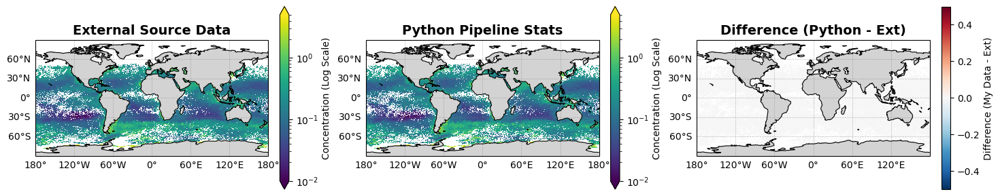

In [17]:
# Open the monthly files
my_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/GLOBAL_4KM_MONTHLY/CHL/M_199801-OCCCI-CHL-GLOBAL-STATS.nc'
ext_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/MONTHLY_CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1M_MONTHLY_4km_GEO_PML_OCx-199801-fv6.0.nc'

ds_my = xr.open_dataset(my_file)
ds_ext = xr.open_dataset(ext_file)

# Align grids and calculate difference
ext_aligned, diff = align_and_difference(
    ds_my=ds_my, 
    ds_ext=ds_ext, 
    var_my='chlor_a_mean', 
    var_ext='chlor_a',
    path_my=my_file,    # 🎯 NEW: Pass paths for xESMF
    path_ext=ext_file   # 🎯 NEW: Pass paths for xESMF
)
# Plot Global Map
# Set vmin/vmax to lock the colorbars so map 1 and map 2 use the same scale!
fig_global = plot_3x1_comparison(
    ds_my['chlor_a_mean'], ext_aligned, diff, 
    region='GLOBAL', 
    log_scale=True,
    vmin=0, vmax=5,        # Data limits (e.g., CHL 0 to 5 mg/m3)
    diff_limit=0.5         # Difference limits (-1.5 to +1.5)
)

  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


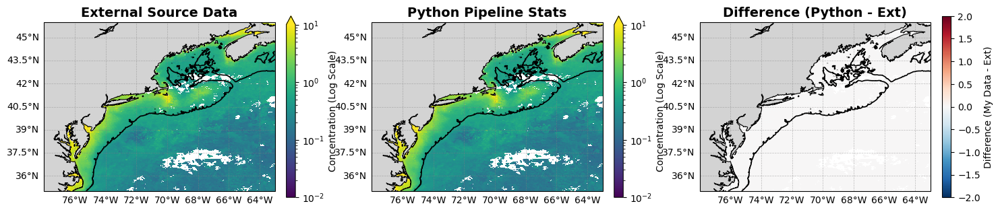

In [18]:
my_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/PRODUCTS/NES_4KM_MONTHLY/CHL/M_199801-OCCCI-CHL-NES-STATS.nc'
ext_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/MONTHLY_CHL/ESACCI-OC-L3S-CHLOR_A-MERGED-1M_MONTHLY_4km_GEO_PML_OCx-199801-fv6.0.nc'

# Open your NES datasets and the bathymetry file
ds_my_nes = xr.open_dataset(my_file)
ds_ext_global = xr.open_dataset(ext_file) 
ds_ext_nes = subset_dataset(ds_ext_global, region='NES')

# Align grids
ext_aligned, diff_nes = align_and_difference(
    ds_my=ds_my_nes, 
    ds_ext=ds_ext_nes, 
    var_my='CHL_mean', 
    var_ext='chlor_a',
    path_my=my_file,    # 🎯 NEW: Pass paths for xESMF
    path_ext=ext_file   # 🎯 NEW: Pass paths for xESMF
)
# Plot NES map with the 200m Isobath!
fig_nes = plot_3x1_comparison(
    ds_my_nes['CHL_mean'], ext_aligned, diff_nes, 
    region='NES', 
    bathy_ds=bathy_ds,     # Pass the bathymetry dataset!
    vmin=0, vmax=10,       # Higher max for coastal CHL
    diff_limit=2.0,
    log_scale=True
)

🌡️ External Data Range: -1.06 to 25.05
🌡️ My Pipeline Range: -1.16 to 25.05
  🔄 Grids do not match. Regridding external data using xESMF...
  ➖ Calculating difference (My Data - External Data)...


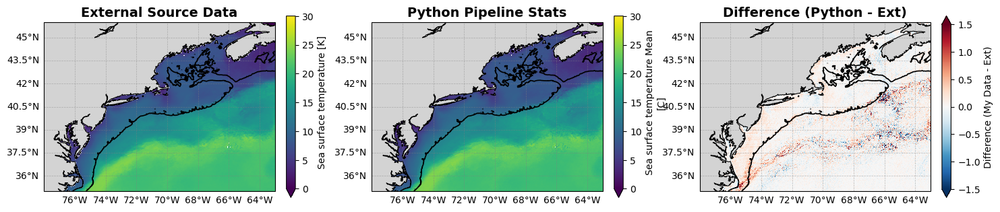

In [19]:
my_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/ACSPO/V2.81/PRODUCTS/NES_2KM_MONTHLY/SST/M_202201-ACSPO-SST-NES-STATS.nc'
ext_file = '/Users/kimberly.hyde/Documents/nadata/DATASETS/ACSPO/V2.81/TEST/MM_202201_202212-ACSPO-V2.81-NESGRID2-SST-STACKED_STATS.nc'

# Open your NES datasets and the bathymetry file
ds_my_nes = xr.open_dataset(my_file)
if 'time' in ds_my_nes.coords:
    ds_my_nes = ds_my_nes.drop_vars('time')
#ds_my_nes['SST_mean'] = ds_my_nes['SST_mean'] - 273.15

ds_ext_stacked = xr.open_dataset(ext_file) 
if 'latitude' in ds_ext_stacked.coords:
    ds_ext_stacked = ds_ext_stacked.rename({'latitude': 'lat', 'longitude': 'lon'})

ds_ext_month = ds_ext_stacked.isel(time=0).squeeze()
if 'time' in ds_ext_month.coords:
    ds_ext_month = ds_ext_month.drop_vars('time')

ds_ext_nes = subset_dataset(ds_ext_month, region='NES')

# Check the raw values
my_min = ds_my_nes['SST_mean'].min().values
my_max = ds_my_nes['SST_mean'].max().values

ext_min = ds_ext_nes['SST_MEAN'].min().values
ext_max = ds_ext_nes['SST_MEAN'].max().values

print(f"🌡️ External Data Range: {ext_min:.2f} to {ext_max:.2f}")
print(f"🌡️ My Pipeline Range: {my_min:.2f} to {my_max:.2f}")

# Align grids
ext_aligned, diff_nes = align_and_difference(
    ds_my=ds_my_nes, 
    ds_ext=ds_ext_nes, 
    var_my='SST_mean', 
    var_ext='SST_MEAN',
    path_my=my_file,    
    path_ext=ext_file   
)
# Plot NES map with the 200m Isobath!
fig_nes = plot_3x1_comparison(
    ds_my_nes['SST_mean'], ext_aligned, diff_nes, 
    region='NES', 
    bathy_ds=bathy_ds,     # Pass the bathymetry dataset!
    vmin=0, vmax=30,       
    diff_limit=1.5,
    log_scale=False
)

In [ ]:
mydir = get_prod_files('CHL',period='M',map_region='NES',getfilepath=True)

In [ ]:
xr.open_dataset('/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/WEEKLY_IDL_CHL/WW_199801_199852-OCCCI-V6.0-NESGRID4-CHLOR_A-CCI-STACKED_STATS.nc')

In [20]:
mydir = get_prod_files('CHL',period='W',map_region='NES',getfilepath=True)
extdir = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/WEEKLY_IDL_CHL'
output_dir = "/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL_IDL_WEEKLY"
ext_stacked_file = f'{extdir}/WW_199801_199852-OCCCI-V6.0-NESGRID4-CHLOR_A-CCI-STACKED_STATS.nc'
my_file = f'{mydir}/W_199801-OCCCI-CHL-NES-STATS.nc'
ds_my = xr.open_dataset(my_file)
ds_ext_stacked = xr.open_dataset(ext_stacked_file)
ds_my

<xarray.Dataset> Size: 5MB
Dimensions:         (time: 1, lat: 312, lon: 432)
Coordinates:
  * lat             (lat) float64 2kB 46.98 46.94 46.9 ... 34.1 34.06 34.02
  * lon             (lon) float64 3kB -78.98 -78.94 -78.9 ... -61.06 -61.02
  * time            (time) datetime64[ns] 8B 1998-01-01
Data variables:
    chlor_a_mean    (time, lat, lon) float32 539kB ...
    chlor_a_min     (time, lat, lon) float32 539kB ...
    chlor_a_max     (time, lat, lon) float32 539kB ...
    chlor_a_median  (time, lat, lon) float32 539kB ...
    chlor_a_std     (time, lat, lon) float32 539kB ...
    chlor_a_sum     (time, lat, lon) float32 539kB ...
    chlor_a_var     (time, lat, lon) float32 539kB ...
    chlor_a_count   (time, lat, lon) float64 1MB ...
Attributes: (12/46)
    conventions:                   CF-1.11, COARDS, ACDD-1.3
    acknowledgement:               The data are sponsored by NOAA and may be ...
    institution:                   DOC | NOAA | National Marine Fisheries Ser...
    naming_authority:              gov.noaa.nefsc
    license:                       The data may be used and redistributed for...
    creator_type:                  group
    ...                            ...
    source_dataset_url:            https://climate.esa.int/en/projects/ocean-...
    source_dataset_reference:      Sathyendranath, S, Brewin, RJW, Brockmann,...
    source_version_url:            https://catalogue.ceda.ac.uk/uuid/9aba59ec...
    source_version_doi:            doi:10.5285/5011d22aae5a4671b0cbc7d05c56c4f0
    source_version_reference:      Sathyendranath, S.; Jackson, T.; Brockmann...
    source_version:                V6.0

📦 Loading stacked external data: /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/WEEKLY_IDL_CHL/WW_199801_199852-OCCCI-V6.0-NESGRID4-CHLOR_A-CCI-STACKED_STATS.nc

📅 Processing Week 199801
  🔄 Grids do not match. Regridding external data using xESMF...
  ➖ Calculating difference (My Data - External Data)...


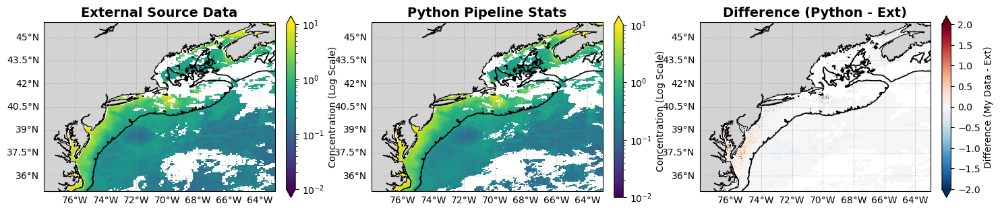

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL_IDL_WEEKLY/CHL_Comparison_W_199801.png

📅 Processing Week 199802
  🔄 Grids do not match. Regridding external data using xESMF...
  ➖ Calculating difference (My Data - External Data)...


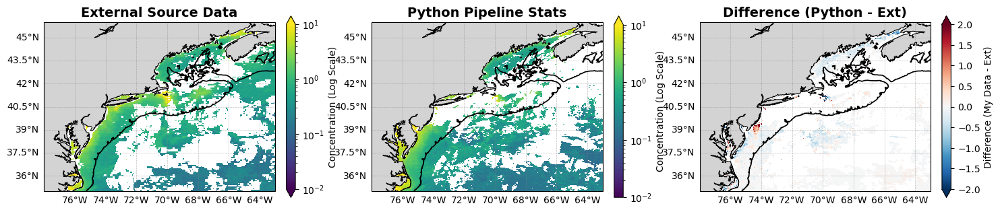

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL_IDL_WEEKLY/CHL_Comparison_W_199802.png

📊 1998 WEEKLY SUMMARY STATISTICS TABLE


NameError: name 'pd' is not defined

In [21]:
year = 1998
mydir = get_prod_files('CHL',period='W',map_region='NES',getfilepath=True)
extdir = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/WEEKLY_IDL_CHL'
output_dir = "/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL_IDL_WEEKLY"

os.makedirs(output_dir, exist_ok=True)
stats_records = []

# 2. Open the stacked external dataset ONCE outside the loop
ext_stacked_file = f'{extdir}/WW_199801_199852-OCCCI-V6.0-NESGRID4-CHLOR_A-CCI-STACKED_STATS.nc'
print(f"📦 Loading stacked external data: {ext_stacked_file}")
ds_ext_stacked = xr.open_dataset(ext_stacked_file)
ds_ext_stacked = ds_ext_stacked.rename({'latitude': 'lat', 'longitude': 'lon'})

# 3. Loop through all 52 weeks
for week in range(1, 3):
    year_week = f"{year}{week:02d}"
    print(f"\n{'='*50}\n📅 Processing Week {year_week}\n{'='*50}")

    my_file = f'{mydir}/W_{year_week}-OCCCI-CHL-NES-STATS.nc'

    if not os.path.exists(my_file):
        print(f"  ⚠️ Missing {my_file}. Skipping.")
        continue

    # Open your weekly pipeline file
    ds_my_nes = xr.open_dataset(my_file)
    if 'time' in ds_my_nes.coords:
        ds_my_nes = ds_my_nes.drop_vars('time')

    # 🎯 4. Extract the matching week from the stacked external dataset
    # (Because Python is 0-indexed, week 1 is at index 0)
    ds_ext_week = ds_ext_stacked.isel(time=week - 1).squeeze()
    if 'time' in ds_ext_week.coords:
        ds_ext_week = ds_ext_week.drop_vars('time')
    
    # 5. Align and calculate difference
    # We pass the path to the stacked file so xESMF can hash its grid!
    ext_nes_aligned, diff_nes = align_and_difference(
        ds_my=ds_my_nes, 
        ds_ext=ds_ext_week, 
        var_my='chlor_a_mean', 
        var_ext='CHLOR_A_MEAN',  
        path_my=my_file,    
        path_ext=ext_stacked_file 
    )

    my_da = ds_my_nes['chlor_a_mean']

    # 6. Generate the Plot
    fig = plot_3x1_comparison(
        my_da, ext_nes_aligned, diff_nes, 
        region='NES', 
        bathy_ds=bathy_ds,     # Assumes bathy_ds is still loaded from the ERDDAP step
        vmin=0.01, vmax=10,    
        diff_limit=2.0,        
        log_scale=True         
    )
    
    plot_path = os.path.join(output_dir, f"CHL_Comparison_W_{year_week}.png")
    fig.savefig(plot_path, bbox_inches='tight', dpi=150)
    plt.close(fig) 
    print(f"  ✅ Saved plot to {plot_path}")

    # 7. Calculate "Apples-to-Apples" overlapping statistics
    valid_mask = np.isfinite(my_da) & np.isfinite(ext_nes_aligned)

    my_vals = my_da.where(valid_mask).values.flatten()
    ext_vals = ext_nes_aligned.where(valid_mask).values.flatten()
    diff_vals = diff_nes.where(valid_mask).values.flatten()

    my_vals = my_vals[~np.isnan(my_vals)]
    ext_vals = ext_vals[~np.isnan(ext_vals)]
    diff_vals = diff_vals[~np.isnan(diff_vals)]

    # Append to stats list
    stats_records.append({
        'Week': year_week,
        'Valid_Pixels': len(my_vals),
        'My_Mean': np.mean(my_vals),
        'Ext_Mean': np.mean(ext_vals),
        'Diff_Mean': np.mean(diff_vals),
        'My_Median': np.median(my_vals),
        'Ext_Median': np.median(ext_vals),
        'Diff_Median': np.median(diff_vals),
        'My_Min': np.min(my_vals),
        'Ext_Min': np.min(ext_vals),
        'Diff_Min': np.min(diff_vals),
        'My_Max': np.max(my_vals),
        'Ext_Max': np.max(ext_vals),
        'Diff_Max': np.max(diff_vals)
    })

    # Close your file, but leave the stacked file open!
    ds_my_nes.close()

# 8. Clean up and export
ds_ext_stacked.close()

print("\n" + "="*50)
print("📊 1998 WEEKLY SUMMARY STATISTICS TABLE")
print("="*50)

df_stats = pd.DataFrame(stats_records)
df_stats.set_index('Week', inplace=True)
df_stats = df_stats.round(4)

display(df_stats)

csv_path = "CHL_Weekly_Validation_Stats_1998.csv"
df_stats.to_csv(csv_path)
print(f"\n✅ Summary statistics successfully saved to {csv_path}")


📅 Processing 199801
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


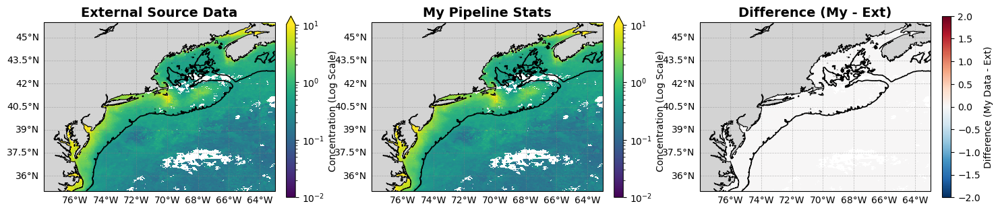

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199801.png

📅 Processing 199802
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


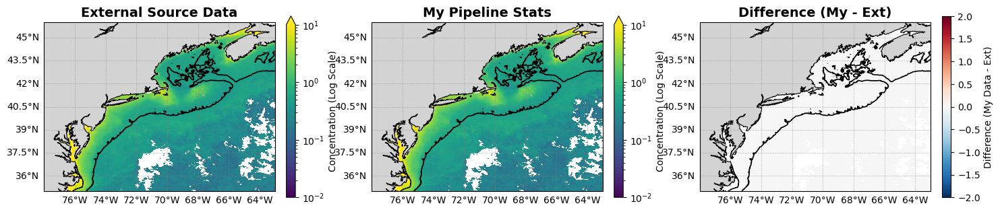

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199802.png

📅 Processing 199803
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


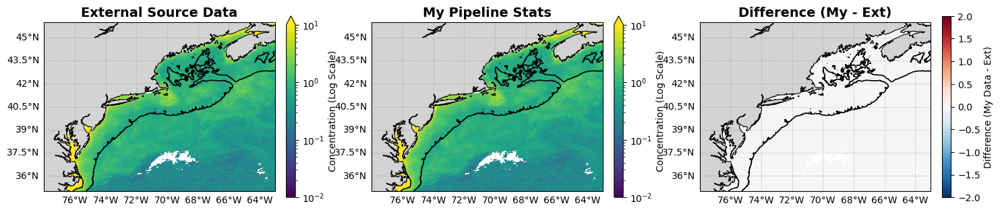

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199803.png

📅 Processing 199804
  ⚠️ Missing files for 199804. Skipping.

📅 Processing 199805
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


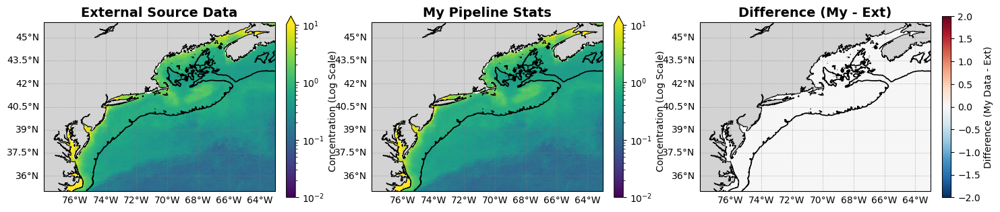

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199805.png

📅 Processing 199806
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


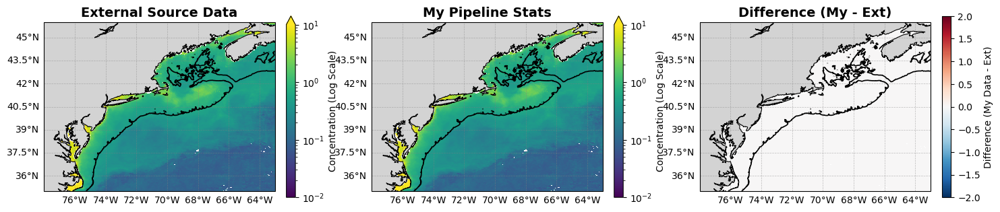

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199806.png

📅 Processing 199807
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


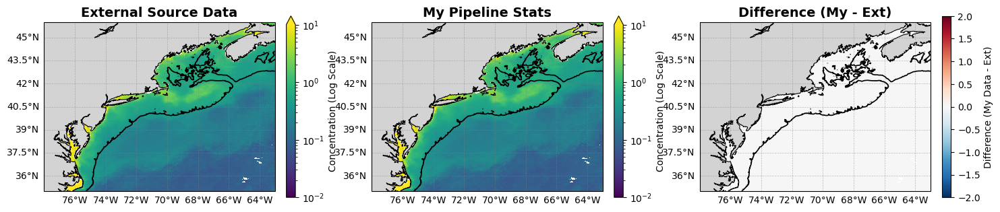

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199807.png

📅 Processing 199808
  ⚠️ Missing files for 199808. Skipping.

📅 Processing 199809
  ⚠️ Missing files for 199809. Skipping.

📅 Processing 199810
  ⚠️ Missing files for 199810. Skipping.

📅 Processing 199811
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


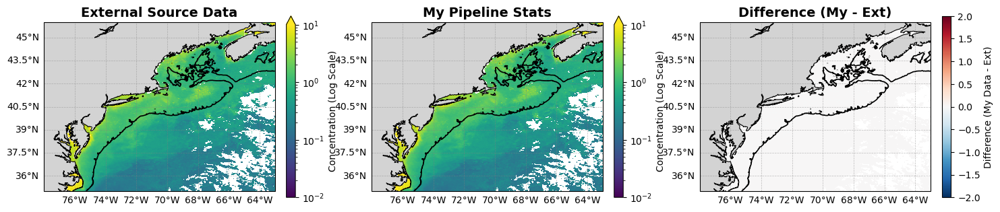

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199811.png

📅 Processing 199812
  ✅ Grids are perfectly aligned. No regridding needed!
  ➖ Calculating difference (My Data - External Data)...


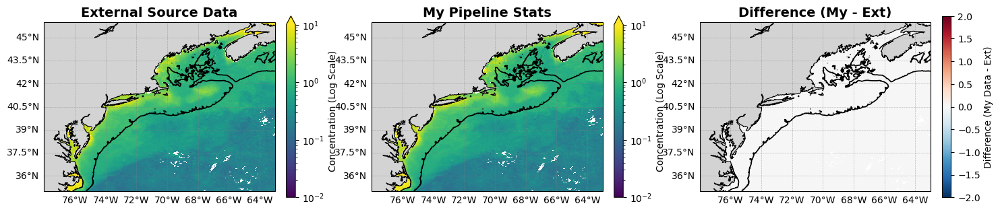

  ✅ Saved plot to /Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL/CHL_Comparison_199812.png

📊 1998 SUMMARY STATISTICS TABLE


NameError: name 'pd' is not defined

In [ ]:
year = 1998
stats_records = []

# Output directory for saving the images (optional but highly recommended!)
mydir = get_prod_files('CHL',period='M',map_region='NES',getfilepath=True)
extdir = '/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/TEST/MONTHLY_CHL'
output_dir = "/Users/kimberly.hyde/Documents/nadata/DATASETS/OCCCI/V6.0/COMPARISONS/CHL"
os.makedirs(output_dir, exist_ok=True)



for month in range(1, 13):
    # Format the year/month string (e.g., "199801")
    year_month = f"{year}{month:02d}"
    print(f"\n{'='*50}\n📅 Processing {year_month}\n{'='*50}")

    # 1. Define file paths (Update these to match your actual file naming conventions!)
    my_file = f'{mydir}/M_{year_month}-OCCCI-CHL-NES-STATS.nc'
    ext_file = f'{extdir}/ESACCI-OC-L3S-CHLOR_A-MERGED-1M_MONTHLY_4km_GEO_PML_OCx-{year_month}-fv6.0.nc'

    # Safely skip if files are missing
    if not os.path.exists(my_file) or not os.path.exists(ext_file):
        print(f"  ⚠️ Missing files for {year_month}. Skipping.")
        continue

    # 2. Open Datasets
    ds_my_nes = xr.open_dataset(my_file)
    ds_ext_global = xr.open_dataset(ext_file)

    # 3. Subset and Align
    ds_ext_nes = subset_dataset(ds_ext_global, region='NES')
    
    ext_nes_aligned, diff_nes = align_and_difference(
        ds_my=ds_my_nes, 
        ds_ext=ds_ext_nes, 
        var_my='CHL_mean', 
        var_ext='chlor_a',
        path_my=my_file,    
        path_ext=ext_file   
    )

    my_da = ds_my_nes['CHL_mean']

    # 4. Generate the Plot
    fig = plot_3x1_comparison(
        my_da, ext_nes_aligned, diff_nes, 
        region='NES', 
        bathy_ds=bathy_ds,     
        vmin=0.01, vmax=10,    
        diff_limit=2.0,        
        log_scale=True         
    )
    
    # Save the plot and close it to prevent Jupyter from crashing due to too many open images
    plot_path = os.path.join(output_dir, f"CHL_Comparison_{year_month}.png")
    fig.savefig(plot_path, bbox_inches='tight', dpi=150)
    plt.close(fig) 
    print(f"  ✅ Saved plot to {plot_path}")

    # 🎯 5. APPLE-TO-APPLES STATISTICS
    # Create a mask that is True ONLY where both datasets have valid (non-NaN) numbers
    valid_mask = np.isfinite(my_da) & np.isfinite(ext_nes_aligned)

    # Extract only the overlapping valid pixels and flatten them into 1D arrays
    my_vals = my_da.where(valid_mask).values.flatten()
    ext_vals = ext_nes_aligned.where(valid_mask).values.flatten()
    diff_vals = diff_nes.where(valid_mask).values.flatten()

    # Drop the NaN values from the 1D arrays so NumPy math works perfectly
    my_vals = my_vals[~np.isnan(my_vals)]
    ext_vals = ext_vals[~np.isnan(ext_vals)]
    diff_vals = diff_vals[~np.isnan(diff_vals)]

    # Append the stats to our master list
    stats_records.append({
        'Month': year_month,
        'Valid_Pixels': len(my_vals),
        'My_Mean': np.mean(my_vals),
        'Ext_Mean': np.mean(ext_vals),
        'Diff_Mean': np.mean(diff_vals),
        'My_Median': np.median(my_vals),
        'Ext_Median': np.median(ext_vals),
        'Diff_Median': np.median(diff_vals),
        'My_Min': np.min(my_vals),
        'Ext_Min': np.min(ext_vals),
        'Diff_Min': np.min(diff_vals),
        'My_Max': np.max(my_vals),
        'Ext_Max': np.max(ext_vals),
        'Diff_Max': np.max(diff_vals)
    })

    # Close the datasets to free up memory!
    ds_my_nes.close()
    ds_ext_global.close()

# 6. Create and display the final summary table
print("\n" + "="*50)
print("📊 1998 SUMMARY STATISTICS TABLE")
print("="*50)

df_stats = pd.DataFrame(stats_records)
df_stats.set_index('Month', inplace=True)

# Round the numbers for a cleaner display
df_stats = df_stats.round(4)

# Display in notebook
display(df_stats)

# Save the table to a CSV file!
csv_path = "CHL_Validation_Stats_1998.csv"
df_stats.to_csv(csv_path)
print(f"\n✅ Summary statistics successfully saved to {csv_path}")

In [31]:
import os
import calendar
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def plot_12_month_composite(data_dir, var_name, mode='climatology', 
                            year=None, year_range="2001_2020", 
                            cmap='viridis', vmin=None, vmax=None, 
                            region_extent=[-78, -63, 35, 46], 
                            file_suffix="-ACSPO-SST-NES-STATS.nc"):
    """
    Creates a 3x4 composite map of 12 months with a single shared colorbar.
    Supports both 'climatology' (MONTH) and 'monthly' (M) file formats.
    """
    if mode == 'monthly' and year is None:
        raise ValueError("❌ You must provide a 'year' (e.g., 2022) when using mode='monthly'.")

    # Set up the 3x4 grid with Cartopy projections
    fig, axes = plt.subplots(3, 4, figsize=(18, 12), 
                             subplot_kw={'projection': ccrs.PlateCarree()})
    axes = axes.flatten()
    mappable = None 

    print(f"🗺️ Generating 3x4 '{mode}' composite for {var_name}...")

    for month in range(1, 13):
        ax = axes[month - 1]
        month_str = f"{month:02d}"
        
        # 🎯 THE FIX: Dynamic File Naming based on the mode
        if mode.lower() == 'monthly':
            filename = f"M_{year}{month_str}{file_suffix}"
        else:
            filename = f"MONTH_{month_str}_{year_range}{file_suffix}"
            
        filepath = os.path.join(data_dir, filename)

        # --- Map Formatting ---
        ax.set_extent(region_extent, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='none', zorder=2)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black', zorder=3)

        gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
        if month % 4 != 1: gl.left_labels = False
        if month <= 8:     gl.bottom_labels = False

        # --- Data Plotting ---
        if not os.path.exists(filepath):
            ax.set_title(calendar.month_name[month], fontsize=14, weight='bold')
            ax.text(0.5, 0.5, "File Missing", transform=ax.transAxes, 
                    ha='center', va='center', fontsize=12, color='red', weight='bold')
            continue

        try:
            ds = xr.open_dataset(filepath).squeeze()
            
            if var_name in ds.data_vars:
                plot = ds[var_name].plot(ax=ax, transform=ccrs.PlateCarree(),
                                         cmap=cmap, vmin=vmin, vmax=vmax,
                                         add_colorbar=False, zorder=1)
                
                # Apply our clean month title AFTER plotting so xarray doesn't overwrite it
                ax.set_title(calendar.month_name[month], fontsize=14, weight='bold')
                
                if mappable is None:
                    mappable = plot
            else:
                print(f"  ⚠️ '{var_name}' not found in {filename}")

            ds.close()

        except Exception as e:
            print(f"  ❌ Error plotting {filename}: {e}")

    # --- Add the Shared Colorbar ---
    if mappable is not None:
        plt.tight_layout()
        fig.subplots_adjust(bottom=0.12)
        cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03]) 
        cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
        cbar.set_label(f"{var_name.replace('_', ' ').title()} (°C)", fontsize=16, weight='bold')
        cbar.ax.tick_params(labelsize=12)

    return fig

🗺️ Generating 3x4 'monthly' composite for SST_mean...
🗺️ Generating 3x4 'monthly' composite for SST_std...


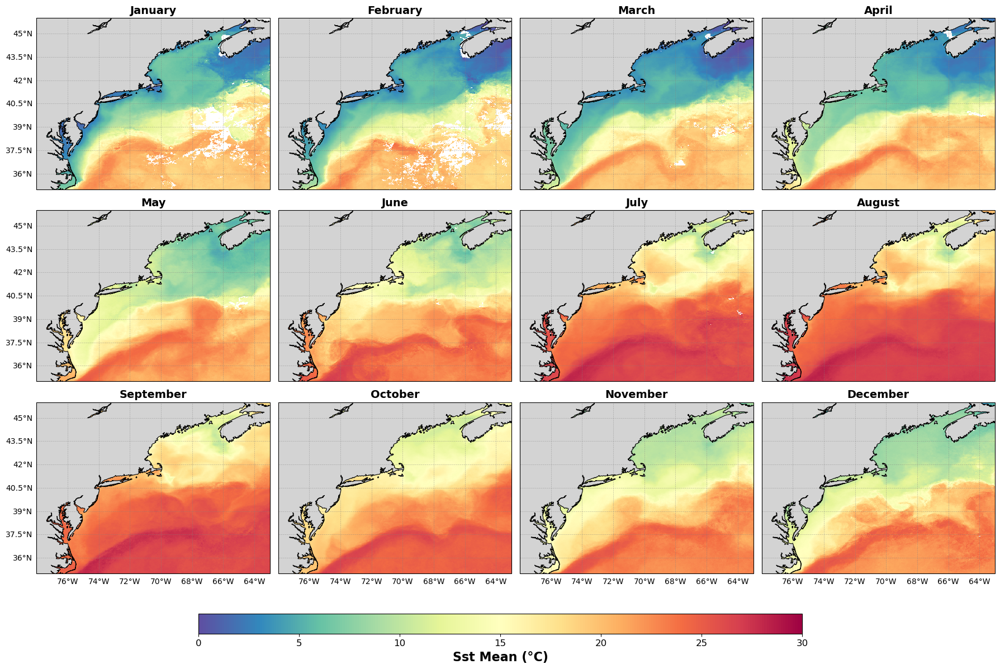

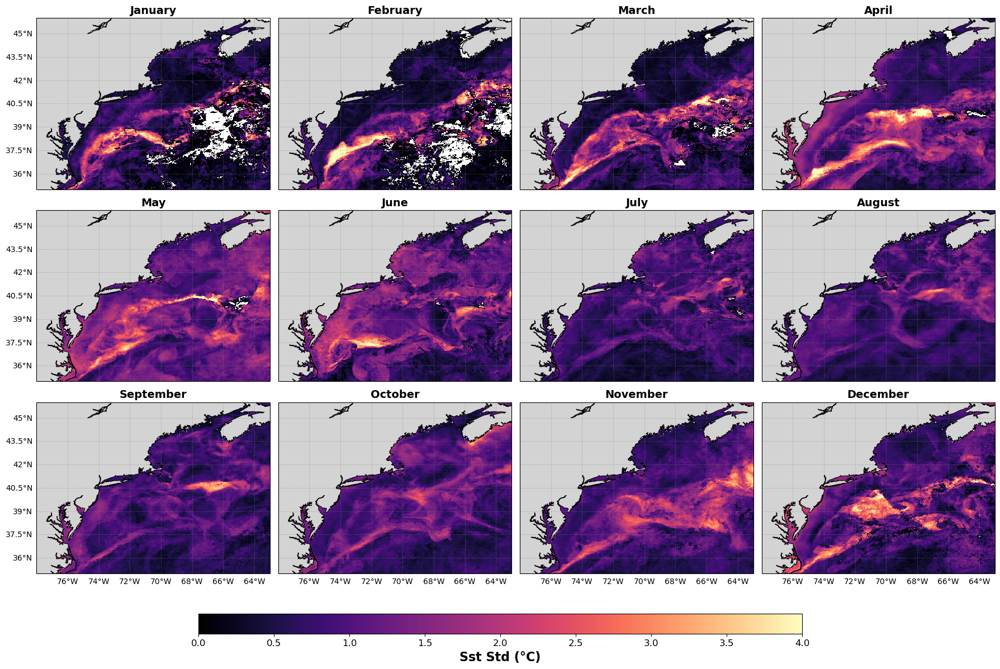

In [34]:
monthly_dir = "/Users/kimberly.hyde/Documents/nadata/DATASETS/ACSPO/V2.81/PRODUCTS/NES_2KM_MONTHLY/SST"
# Plot the 2022 Standard Deviation
fig_monthly_std = plot_12_month_composite(
    data_dir=monthly_dir,
    var_name='SST_mean',
    mode='monthly',        # 🎯 Switch to Monthly mode
    year=2001,             # Provide the year you want to plot
    cmap='Spectral_r',
    vmin=0, vmax=30
)

# Plot the 2001 Standard Deviation
fig_monthly_std = plot_12_month_composite(
    data_dir=monthly_dir,
    var_name='SST_std',
    mode='monthly',        # 🎯 Switch to Monthly mode
    year=2001,             # Provide the year you want to plot
    cmap='magma',
    vmin=0, vmax=4
)

fig_monthly_std.savefig("NES_SST_StdDev_2022.png", dpi=200, bbox_inches='tight')

In [27]:
import math
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def plot_stats_diagnostic(filepath, base_var='SST', region_extent=[-78, -63, 35, 46]):
    """
    Plots a comprehensive diagnostic grid of all statistical variables 
    found in a single pipeline output file.
    """
    print(f"📦 Loading diagnostic file: {filepath}")
    
    # Squeeze to ensure we are working with pure 2D maps
    ds = xr.open_dataset(filepath).squeeze()

    # Find all stats variables for the base product (e.g., SST_mean, SST_std, SST_count)
    stats_vars = [v for v in ds.data_vars if v.startswith(base_var)]

    if not stats_vars:
        print(f"❌ No variables starting with '{base_var}' found in the dataset.")
        return

    n_vars = len(stats_vars)
    cols = 4
    rows = math.ceil(n_vars / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), 
                             subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Flatten axes so we can easily loop through them
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < n_vars:
            var_name = stats_vars[i]
            data = ds[var_name]

            # --- 🎯 Dynamic Aesthetics Logic ---
            stat_type = var_name.split('_')[-1]

            if stat_type in ['std', 'var']:
                cmap = 'magma'
                vmin = 0
                # Auto-scale upper bound safely (avoids crashing if max is 0!)
                vmax = float(data.quantile(0.99)) if data.max() > 0 else 1.0 
            elif stat_type == 'count':
                cmap = 'viridis'
                vmin = 0
                vmax = float(data.max()) # Max count (e.g. 31 for a month, ~600 for a 20yr clim)
            else: 
                # Catch-all for temperatures (mean, median, min, max)
                cmap = 'Spectral_r'
                vmin = 0
                vmax = 30

            # --- Map Formatting ---
            ax.set_extent(region_extent, crs=ccrs.PlateCarree())
            ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
            ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
            
            gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
            gl.top_labels = False
            gl.right_labels = False

            # --- Plot the Data ---
            plot = data.plot(ax=ax, transform=ccrs.PlateCarree(),
                             cmap=cmap, vmin=vmin, vmax=vmax,
                             add_colorbar=False, zorder=1)

            # Add an individual colorbar hugged tightly to the bottom of the axis
            cbar = plt.colorbar(plot, ax=ax, orientation='horizontal', pad=0.08, fraction=0.05)
            cbar.set_label(f"{var_name}", weight='bold')

            # Clean Title
            ax.set_title(var_name.replace('_', ' ').title(), weight='bold', fontsize=14)
            
        else:
            # Hide unused axes if we have fewer than 8 variables
            ax.axis('off')

    plt.tight_layout()
    return fig

📦 Loading diagnostic file: /Users/kimberly.hyde/Documents/nadata/DATASETS/ACSPO/V2.81/PRODUCTS/NES_2KM_MONTHLY/SST/M_200101-ACSPO-SST-NES-STATS.nc


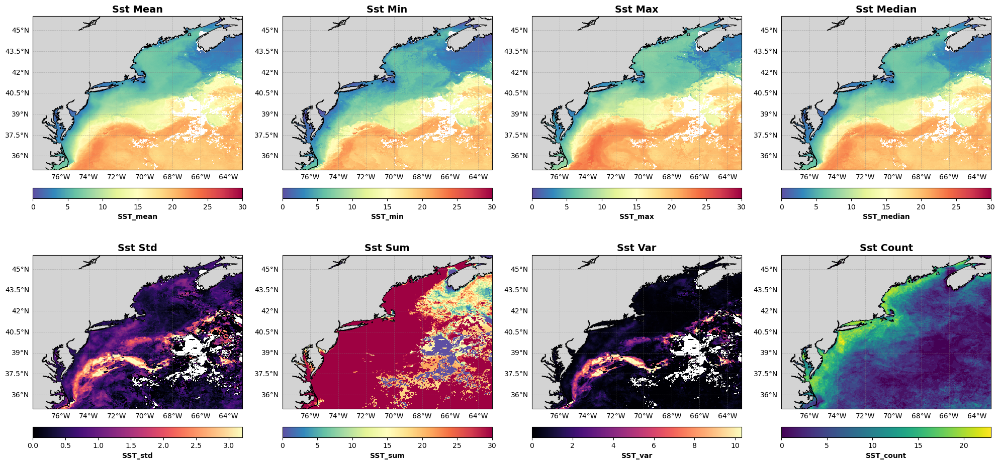

In [29]:
# Pick a random Monthly file to inspect
diagnostic_file = "/Users/kimberly.hyde/Documents/nadata/DATASETS/ACSPO/V2.81/PRODUCTS/NES_2KM_MONTHLY/SST/M_200101-ACSPO-SST-NES-STATS.nc"

fig_diag = plot_stats_diagnostic(diagnostic_file, base_var='SST')
fig_diag.savefig("Diagnostic_Monthly_Stats.png", dpi=150, bbox_inches='tight')